# Driver Drowsiness Detection — CNN-LSTM (Colab experiments)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Osama-kn/ddd/blob/main/notebooks/DDD.ipynb)

This notebook is the original exploration: it downloads the [Driver Drowsiness Dataset (DDD)](https://www.kaggle.com/datasets/ismailnasri20/driver-drowsiness-dataset-ddd) from Kaggle, explores it and trains a first CNN-LSTM.

**Notes**
- Class index `0` = *Non Drowsy*, `1` = *Drowsy* (the order of `category_folders`).
- Images are split at random and sequences are made by grouping consecutive rows of the shuffled training set, so frames of the same person appear in both train and validation. The ~99.9% validation accuracy below is therefore optimistic.
- The production pipeline in this repository (`python main.py train`) fixes both points: it builds sequences from consecutive frames of the same subject and validates on **unseen subjects** by default.
- You need a `kaggle.json` API token (Kaggle → Settings → API). Never commit it.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

In [5]:
# Upload kaggle.json from your Kaggle account settings
from google.colab import files
files.upload()

# Setup Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


Saving kaggle.json to kaggle (2).json


In [6]:

# Download the dataset
!kaggle datasets download -d ismailnasri20/driver-drowsiness-dataset-ddd
!unzip driver-drowsiness-dataset-ddd.zip -d driver-drowsiness-dataset-ddd

Dataset URL: https://www.kaggle.com/datasets/ismailnasri20/driver-drowsiness-dataset-ddd
License(s): unknown
User cancelled operation
Archive:  driver-drowsiness-dataset-ddd.zip
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0001.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0002.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0003.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0004.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0005.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0006.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0007.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (DDD)/Drowsy/A0008.png  
  inflating: driver-drowsiness-dataset-ddd/Driver Drowsiness Dataset (

In [2]:
base_dir = "/content/driver-drowsiness-dataset-ddd"
categories = ["Alert", "Drowsy"]
category_folders = ["Non Drowsy", "Drowsy"]
img_size = (48, 48)
data = []


In [3]:
# Load images and label them
for label, folder in enumerate(category_folders):
    folder_path = os.path.join(base_dir, folder)
    for file in os.listdir(folder_path):
        if file.endswith(".jpg") or file.endswith(".png"):
            file_path = os.path.join(folder_path, file)
            data.append((file_path, label))


# Check dataset stats
print(f"Total images: {len(data)}")
print(f"Alert (0): {sum(1 for _, l in data if l == 0)}")
print(f"Drowsy (1): {sum(1 for _, l in data if l == 1)}")



Total images: 41793
Alert (0): 19445
Drowsy (1): 22348


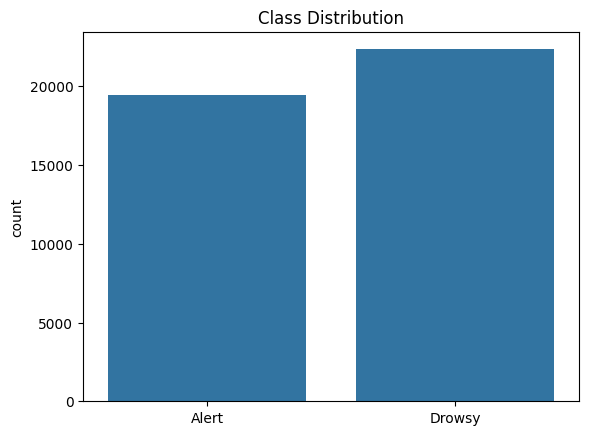

In [4]:
# Class distribution
labels = [label for _, label in data]
sns.countplot(x=labels)
plt.xticks([0, 1], categories)
plt.title("Class Distribution")
plt.show()

In [6]:
from PIL import Image

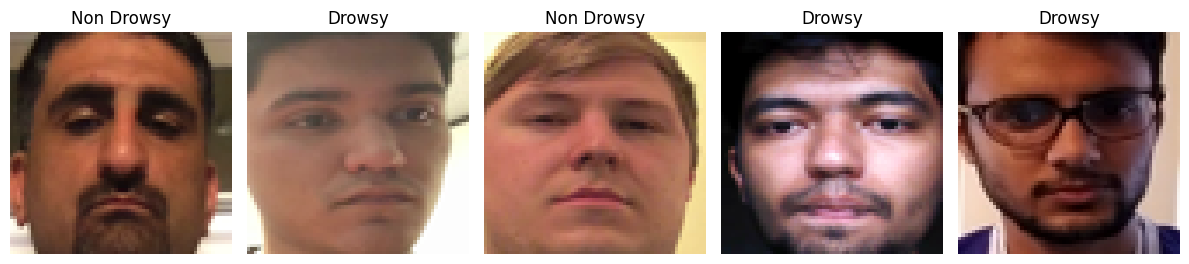

In [10]:
# Visualize sample images
def show_images(data_subset, title):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle(title, fontsize=16)
    for i, ax in enumerate(axes.flat):
        img = Image.open(data_subset[i][0])
        ax.imshow(img)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_images([x for x in data if x[1] == 0][:10], "Alert (Non Drowsy) Samples")
show_images([x for x in data if x[1] == 1][:10], "Drowsy Samples")

In [7]:
IMG_SIZE = (64, 64)

# Convert images to arrays
X = []
y = []

for file_path, label in data:
    try:
        img = Image.open(file_path).convert('RGB').resize(IMG_SIZE)
        X.append(np.array(img))
        y.append(label)
    except Exception as e:
        print(f"Error loading image {file_path}: {e}")

X = np.array(X, dtype="float32") / 255.0  # Normalize
y = to_categorical(np.array(y), num_classes=2)  # One-hot encode

print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")


Shape of X: (41793, 64, 64, 3)
Shape of y: (41793, 2)


In [8]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Training samples: {X_train.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")

Training samples: 33434
Validation samples: 8359


In [ ]:
# Display a few example images
def show_sample_images(X, y, class_names, num_samples=5):
    plt.figure(figsize=(12, 4))
    for i in range(num_samples):
        idx = np.random.randint(0, len(X))
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(X[idx])
        label_index = np.argmax(y[idx])
        plt.title(class_names[label_index])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

class_names = ['Non Drowsy', 'Drowsy']  # index 0 = 'Non Drowsy' folder, 1 = 'Drowsy'
show_sample_images(X_train, y_train, class_names)

In [11]:
sequence_length = 8
timesteps = sequence_length
input_shape = (timesteps, 8, 8, 3)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import TimeDistributed, Conv2D, MaxPooling2D, Flatten, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [19]:
# Reshape images for LSTM: (num_samples, timesteps, height, width, channels)
timesteps = 4
X_train_seq = X_train.reshape(-1, timesteps, 16, 16, 3)
X_val_seq = X_val.reshape(-1, timesteps, 16, 16, 3)
y_train_seq = y_train[:X_train_seq.shape[0]]
y_val_seq = y_val[:X_val_seq.shape[0]]

print("X_train_seq shape:", X_train_seq.shape)

model = Sequential([
    TimeDistributed(Conv2D(32, (3, 3), activation='relu'), input_shape=(timesteps, 16, 16, 3)),
    TimeDistributed(MaxPooling2D((2, 2))),
    TimeDistributed(Flatten()),
    LSTM(64),
    Dropout(0.5),
    Dense(2, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer=Adam(1e-4), metrics=['accuracy'])
model.summary()


X_train_seq shape: (133736, 4, 16, 16, 3)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_3              │ (None, 4, 14, 14, 32)  │           896 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 4, 7, 7, 32)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 4, 1568)        │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │       418,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 419,074 (1.60 MB)

 Trainable params: 419,074 (1.60 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
print(X_train.shape)  # e.g. (N, H, W, 3)
print(X_val.shape)

(33434, 64, 64, 3)
(8359, 64, 64, 3)


In [26]:
# Set parameters
timesteps = 4
H, W = 64, 64

# Calculate how many complete sequences we can make
train_seq_count = X_train.shape[0] // timesteps
val_seq_count = X_val.shape[0] // timesteps

# Cut data to be multiple of timesteps
X_train_seq = X_train[:train_seq_count * timesteps].reshape(train_seq_count, timesteps, H, W, 3)
y_train_seq = y_train[:train_seq_count * timesteps].reshape(train_seq_count, timesteps, y_train.shape[1])
y_train_seq = y_train_seq[:, -1, :]  # Use last label in sequence

X_val_seq = X_val[:val_seq_count * timesteps].reshape(val_seq_count, timesteps, H, W, 3)
y_val_seq = y_val[:val_seq_count * timesteps].reshape(val_seq_count, timesteps, y_val.shape[1])
y_val_seq = y_val_seq[:, -1, :]


In [29]:
from tensorflow.keras.layers import TimeDistributed, Conv2D, MaxPooling2D, Flatten, LSTM, Dense, Input
from tensorflow.keras.models import Model

input_shape = (timesteps, H, W, 3)  # e.g., (4, 64, 64, 3)

inputs = Input(shape=input_shape)

# Apply CNN frame-wise using TimeDistributed
x = TimeDistributed(Conv2D(32, (3,3), activation='relu'))(inputs)
x = TimeDistributed(MaxPooling2D((2,2)))(x)
x = TimeDistributed(Conv2D(64, (3,3), activation='relu'))(x)
x = TimeDistributed(MaxPooling2D((2,2)))(x)
x = TimeDistributed(Flatten())(x)  # This flattens the CNN output per frame

# Now LSTM receives (batch_size, timesteps, features)
x = LSTM(64)(x)

outputs = Dense(2, activation='softmax')(x)

model = Model(inputs, outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [30]:
history = model.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=10,
    batch_size=32
)


Epoch 1/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 425s 2s/step - accuracy: 0.7340 - loss: 0.4886 - val_accuracy: 0.9966 - val_loss: 0.0178
Epoch 2/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 440s 2s/step - accuracy: 0.9951 - loss: 0.0192 - val_accuracy: 0.9952 - val_loss: 0.0205
Epoch 3/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - accuracy: 0.9899 - loss: 0.0305 - val_accuracy: 0.9981 - val_loss: 0.0055
Epoch 4/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 440s 2s/step - accuracy: 0.9997 - loss: 0.0020 - val_accuracy: 0.9986 - val_loss: 0.0061
Epoch 5/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 445s 2s/step - accuracy: 0.9997 - loss: 9.7499e-04 - val_accuracy: 0.9986 - val_loss: 0.0062
Epoch 6/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 414s 2s/step - accuracy: 1.0000 - loss: 2.2650e-04 - val_accuracy: 0.9981 - val_loss: 0.0052
Epoch 7/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 443s 2s/step - accuracy: 1.0000 - loss: 1.7839e-04 - val_accuracy: 0.9981 - val_loss: 0.0047
Epoch 8/10
262/262 ━━━━━━━━━━━━━━━━━━━━ 443s 2s/step - accuracy: 1.0000 - loss: 1.467

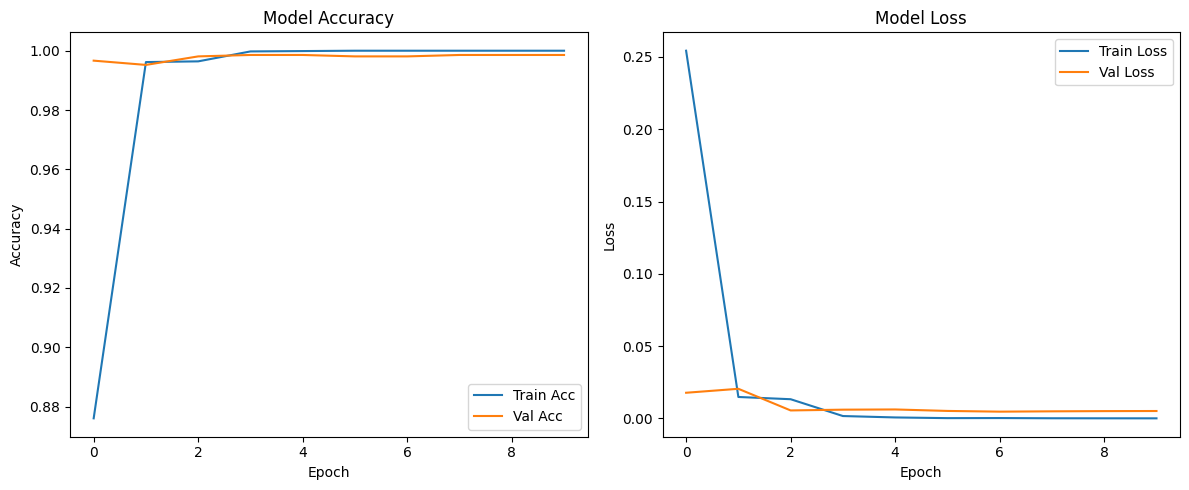

In [31]:
plt.figure(figsize=(12, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [32]:
model.save("cnn_lstm_drowsiness_model.h5")